# Mining strategies: how RaMiCo chooses its pairs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ClaudioDaka99/RaMiCo/blob/main/examples/02_mining_strategies.ipynb)

RaMiCo's rules come from pairs of samples: a *factual* of one class and a *counterfactual* of another. Which pairs
are mined decides which rules come out. The paper proposes three **mining strategies** and an **ensemble** of them;
this notebook shows what each one selects and compares the rules they produce on the same model, over many random
splits of **Adult**, the census-income data of the UCI repository and the largest dataset of the paper.

**In this notebook you will**

1. see, on a map of a two-feature dataset, which pairs each strategy chooses;
2. extract the rules of the four strategies over several seeds and compare fidelity, incomprehensibility and implausibility, with significance tests;
3. read the trade-off between faithful and concise rules on a Pareto chart.

| | |
|---|---|
| **Prerequisites** | Python ≥ 3.11, `pip install "ramico[tutorials]"`; tutorial [01](01_quickstart.ipynb) for the basics |
| **Duration** | about 3 hours for 30 seeds on a laptop (resumable), or load the published results; 3 minutes with `QUICK = True` |
| **Hardware** | any laptop with 8 GB of memory, no GPU needed |

In [1]:
# On Colab, install RaMiCo and the libraries of the tutorials first
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "ramico[tutorials]"

In [2]:
QUICK = False  # 3,000 people, 3 seeds, fewer factuals and counterfactuals
SEED = 42
MODEL = "xgboost"  # black box of the paper: "xgboost" or "mlp"
N_SEEDS = 30  # random splits of the comparison, as in the paper
DEVICE = "auto"  # XGBoost device: "auto", "cpu" or "cuda"

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
from great_tables import GT
from sklearn.compose import make_column_transformer
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

from ramico import RaMiCo, datasets, viz
from ramico.benchmark import balanced_split, compare_strategies, paper_seeds, run_benchmark

if MODEL not in ("xgboost", "mlp"):
    raise ValueError(f'MODEL must be "xgboost" or "mlp", not {MODEL!r}')
if MODEL == "mlp":  # the resampling of the paper's MLP on Adult
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import make_pipeline as make_resampling_pipeline
    from imblearn.under_sampling import RandomUnderSampler

viz.theme.apply()
N_FACTUALS, N_COUNTERFACTUALS = (25, 10) if QUICK else (100, 50)  # s and k in the paper
SEEDS = paper_seeds(3 if QUICK else N_SEEDS)  # the seeds of the paper's experiments
STRATEGIES = ["ensemble", "boundary", "prototype", "random"]
XGB_DEVICE = "cpu" if DEVICE == "auto" else DEVICE
MODEL_NAME = {"xgboost": "XGBoost", "mlp": "MLP"}[MODEL]
CACHE = Path("cache") / f"02_adult_{MODEL}_{'quick' if QUICK else 'full'}"  # one file per seed and strategy
print(f"{len(SEEDS)} seeds · {N_FACTUALS} factuals and {N_COUNTERFACTUALS} counterfactuals per class")

30 seeds · 100 factuals and 50 counterfactuals per class


## 1. People and model

`ramico.datasets.load_adult` downloads the UCI file once, checks its checksum and drops the rows with missing values:
30,162 people, 14 features, of which 8 categorical, and whether they earn more than 50,000 dollars a year, true for
about a quarter of them. The quick run keeps a stratified sample of 3,000 people.

The black box is one of the two pipelines the paper's experiments used for Adult, behind one-hot encoding and
standardisation. `MODEL`, in the first code cell, chooses:

- `"xgboost"`: 500 trees of depth 6, the positive class weighted three times, the run shown here;
- `"mlp"`: the training data are rebalanced first, undersampling the majority class to twice the minority and then
  oversampling the minority with SMOTE, and a multilayer perceptron with one hidden layer of 512 units learns from
  them.

`make_model(seed)` builds the pipeline unfitted, so that every random split trains its own model. The comments below
describe the XGBoost run.

In [4]:
data = datasets.load_adult()
X, y = data
if QUICK:
    keep, _ = train_test_split(np.arange(len(y)), train_size=3000, stratify=y, random_state=SEED)
    X, y = X.iloc[np.sort(keep)], y.iloc[np.sort(keep)]
categorical = data.categorical_features
numerical = [c for c in X.columns if c not in categorical]


def make_model(seed):
    """The pipeline of the paper's experiments for Adult, unfitted."""
    encode = make_column_transformer(
        (OneHotEncoder(handle_unknown="ignore"), categorical), (StandardScaler(), numerical)
    )
    if MODEL == "mlp":
        return make_resampling_pipeline(
            encode,
            RandomUnderSampler(sampling_strategy=0.5, random_state=seed),
            SMOTE(random_state=seed),
            MLPClassifier(hidden_layer_sizes=(512,), alpha=0.2, batch_size=128, max_iter=1000, random_state=seed),
        )
    return make_pipeline(
        encode,
        XGBClassifier(
            n_estimators=500,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            gamma=0.1,
            min_child_weight=5,
            reg_alpha=0.1,
            reg_lambda=1.5,
            scale_pos_weight=3,
            eval_metric="logloss",
            tree_method="hist",
            device=XGB_DEVICE,
            random_state=seed,
        ),
    )


print(f"{len(X):,} people, {X.shape[1]} features ({len(categorical)} categorical) · {y.mean():.0%} earn more than 50K")

30,162 people, 14 features (8 categorical) · 25% earn more than 50K


## 2. Four ways of choosing pairs

For each class *c* a strategy picks factuals in *X_c*, the samples of class *c*, and counterfactuals in *X≠c*, the
samples of the other classes:

| Strategy | Factuals | Counterfactuals | What the rules describe |
|---|---|---|---|
| `boundary` | drawn among the samples of *X_c* closest to *X≠c* | the *k* nearest in *X≠c* | small changes near the decision boundary |
| `prototype` | *s* medoids of *X_c* | *k* medoids of *X≠c*, shared by all factuals | typical members of each class |
| `random` | drawn at random from *X_c* | the *k* nearest in *X≠c* | an unbiased sample of the class |
| `ensemble` | prototype + nearest-boundary + random-pairs, each keeping its rules | | the reference configuration of the paper |

`RaMiCo.pairs` returns the pairs a strategy chooses, without extracting rules: with an integer `random_state` they are
the pairs `fit` would use, and no model is needed. People described by 14 features cannot be drawn on a page
without distorting their distances, so the map below uses a toy dataset with two numerical features, where it is
exact: two interleaved half-moons, classes A and B. Each strategy picks 6 factuals of class B and 3 counterfactuals
for each.

The map is not part of RaMiCo: the next cell draws it with plotly from the output of `RaMiCo.pairs`, an example
of the analyses the pairs allow.

In [5]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def plot_pairs(X, y, pairs, mined_class, class_names):
    """The pairs of each strategy on the map of two numerical features, one panel per strategy.

    The factuals of `mined_class` (red) are joined to their counterfactuals (blue); the pairs of the components of an
    ensemble take the colour of their component.
    """
    red, blue = viz.theme.CATEGORICAL["light"][7], viz.theme.CATEGORICAL["light"][0]
    ink = viz.theme.INK["light"]
    x, y_axis = X.columns
    inside = np.asarray(y == mined_class)
    rows = -(-len(pairs) // 2)
    figure = make_subplots(
        rows=rows, cols=2, subplot_titles=list(pairs), horizontal_spacing=0.04, vertical_spacing=0.08
    )
    in_legend = set()

    def add(trace, row, col, rank, legend="legend"):
        """Add a trace, with its legend entry the first time only."""
        trace.update(legendgroup=trace.name, showlegend=trace.name not in in_legend, legendrank=rank, legend=legend)
        in_legend.add(trace.name)
        figure.add_trace(trace, row=row, col=col)

    for i, chosen in enumerate(pairs.values()):
        row, col = i // 2 + 1, i % 2 + 1
        chosen = chosen[chosen["class"] == mined_class]
        for mask, colour, label, rank in (
            (inside, red, f"{class_names[mined_class]} (X_c)", 1),
            (~inside, blue, "other classes (X≠c)", 2),
        ):
            samples = X[mask]
            marker = dict(size=6, color=colour, opacity=0.28, line=dict(width=0))
            add(go.Scatter(x=samples[x], y=samples[y_axis], mode="markers", name=label, marker=marker), row, col, rank)
        components = list(dict.fromkeys(chosen["strategy"]))
        colours = viz.theme.strategy_colors(components)
        for component in components:
            part = chosen[chosen["strategy"] == component]
            gap = np.full(len(part), np.nan)  # one segment per pair
            ends = [X.loc[part[end]].to_numpy() for end in ("factual", "counterfactual")]
            segments = np.stack([ends[0], ends[1], np.column_stack([gap, gap])], axis=1).reshape(-1, 2)
            several = len(components) > 1
            line = dict(color=colours[component] if several else ink["secondary"], width=1.2)
            name = f"pair · {component}" if several else "pair"
            trace = go.Scatter(x=segments[:, 0], y=segments[:, 1], mode="lines", name=name, line=line,
                               opacity=0.8 if several else 0.6, hoverinfo="skip")  # fmt: skip
            add(trace, row, col, 5 + viz.theme.strategy_sort_key(component)[0], legend="legend2")
        for end, colour, rank in (("counterfactual", blue, 4), ("factual", red, 3)):
            samples = X.loc[chosen[end].unique()]
            marker = dict(size=11, color=colour, line=dict(width=2, color=ink["primary"]))
            add(go.Scatter(x=samples[x], y=samples[y_axis], mode="markers", name=end, marker=marker), row, col, rank)
    figure.update_xaxes(title=dict(text=x, font=dict(size=12)), row=rows)
    figure.update_yaxes(title=dict(text=y_axis, font=dict(size=12)), col=1)
    figure.update_annotations(font=dict(size=14, color=ink["primary"]))
    name = class_names[mined_class]
    figure.update_layout(
        title=(
            "How the strategies choose their pairs<br><span style='font-size:12px;color:"
            f"{ink['secondary']}'>factuals of class {name} (X_c, red) joined to their counterfactuals "
            "(X≠c, blue) · map: the two features</span>"
        ),
        # two legends, one row each: the samples, then the pairs
        legend=dict(orientation="h", yanchor="top", y=-56 / (380 * rows - 60), x=0),
        legend2=dict(
            orientation="h",
            yanchor="top",
            y=-84 / (380 * rows - 60),
            x=0,
            font=dict(color=ink["secondary"]),
            bgcolor="rgba(0,0,0,0)",
        ),
        height=230 + 380 * rows,
        margin=dict(t=110, b=130),
    )
    return figure

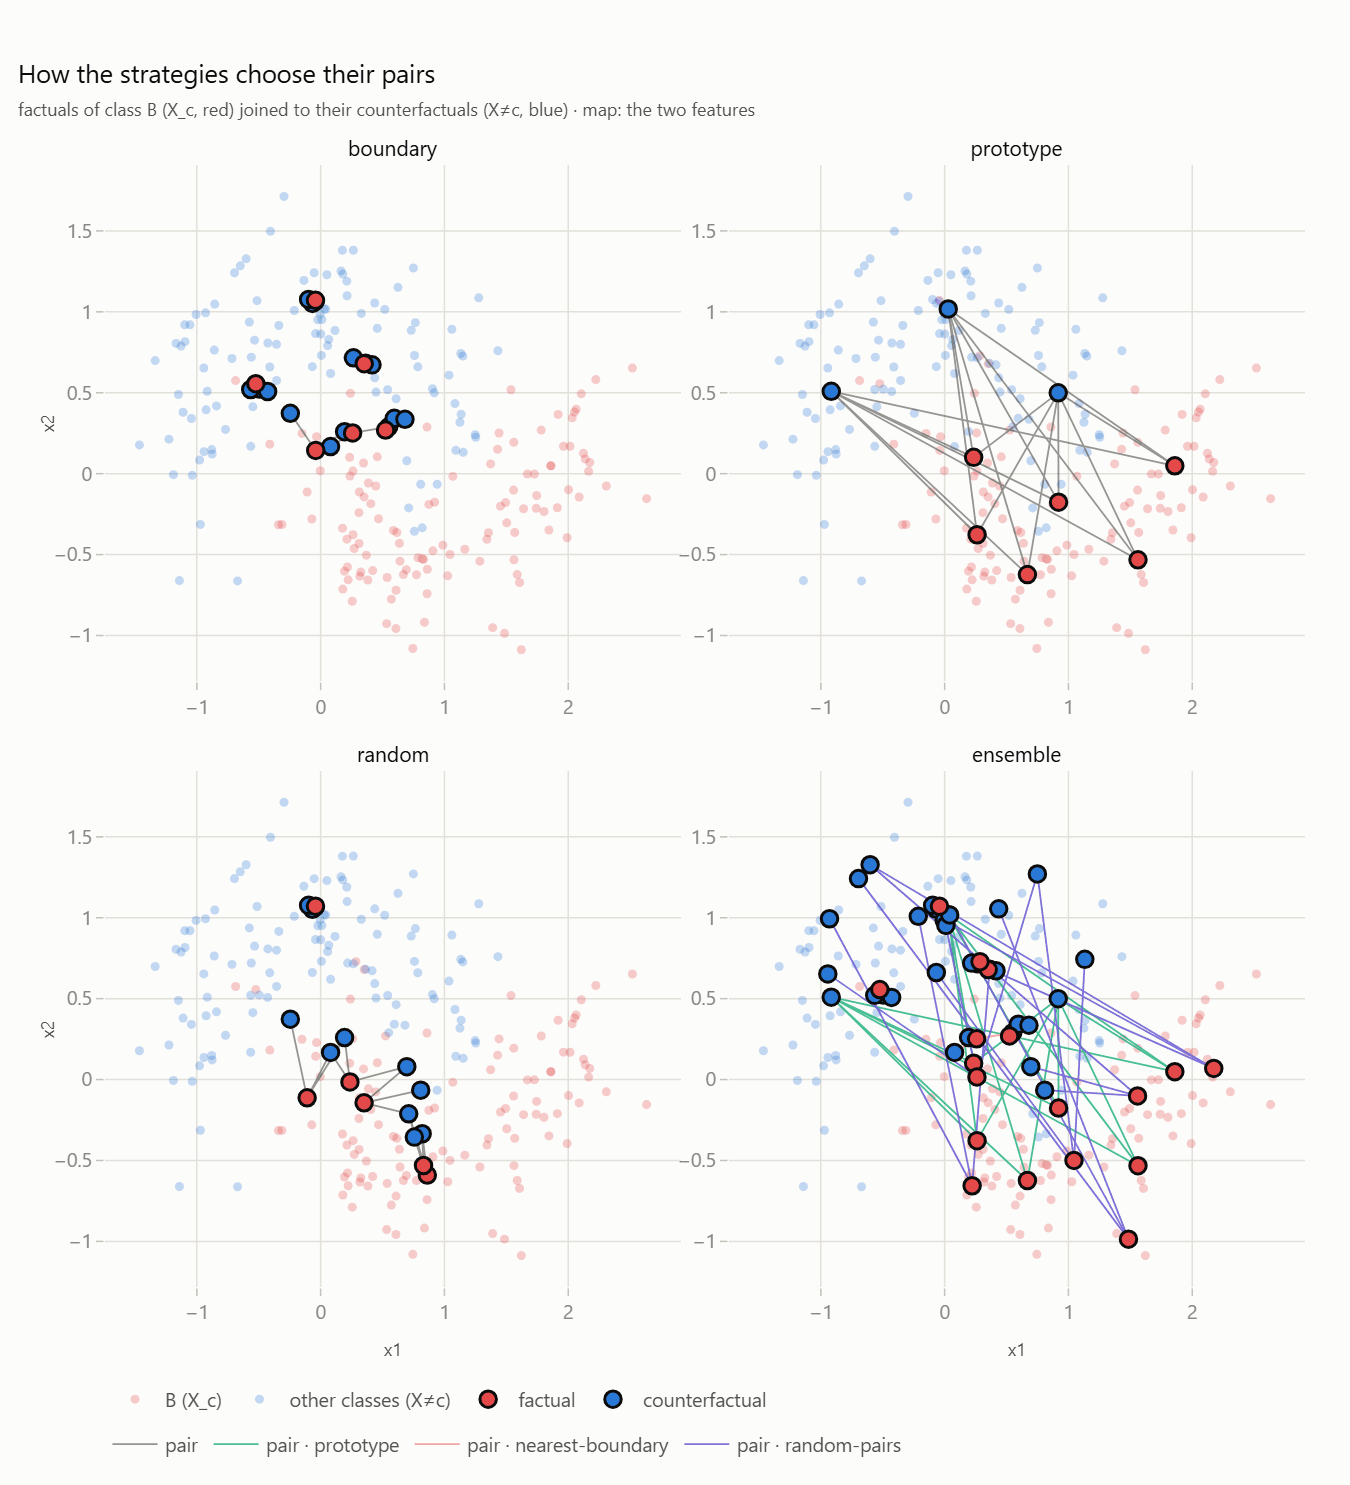

In [6]:
points, labels = make_moons(n_samples=240, noise=0.3, random_state=0)
moons, moon_class = pd.DataFrame(points, columns=["x1", "x2"]), pd.Series(labels)
pairs = {
    name: RaMiCo(None, strategy=name, n_factuals=6, n_counterfactuals=3, random_state=SEED).pairs(moons, moon_class)
    for name in ["boundary", "prototype", "random", "ensemble"]
}
viz.show(plot_pairs(moons, moon_class, pairs, mined_class=1, class_names={0: "A", 1: "B"}))

- **Boundary** factuals are drawn among the samples of B closest to A, where the moons meet, and each is joined to
  its nearest samples of A: short lines across the border.
- **Prototype** factuals are medoids, typical samples spread over B, and all of them are paired with the same three
  medoids of A.
- **Random** factuals fall anywhere in B, each with its own nearest samples of A.
- The **ensemble** runs three components, each with its own pairs, in colour: prototype mining, *nearest-boundary*
  mining, the deterministic variant of boundary mining that takes the samples of B closest to A, and *random-pairs*
  mining, which pairs random factuals with random counterfactuals, hence its long lines across the map.

## 3. Comparing the strategies

`run_benchmark` repeats the paper's protocol for each seed: a split that holds out 10% of the people of each class as a
balanced test set (`balanced_split`, as in the paper for Adult), a model trained on the rest, the rules of every
strategy extracted from the training people and scored on them with the three metrics. Each result is saved in
`examples/cache/` as soon as it is computed, so an interrupted run resumes where it stopped.

The full run takes about 3 hours on a laptop. To skip it, load the results of the published run instead by removing
the `#` in the next cell.

In [7]:
results = None
# the published full run, with XGBoost:
# MODEL_NAME = "XGBoost"
# results = pd.read_csv("https://raw.githubusercontent.com/ClaudioDaka99/RaMiCo/main/examples/results/02_mining_strategies.csv")

In [8]:
if results is None:
    results = run_benchmark(
        make_model,
        X,
        y,
        strategies=STRATEGIES,
        seeds=SEEDS,
        n_factuals=N_FACTUALS,
        n_counterfactuals=N_COUNTERFACTUALS,
        split=balanced_split(0.1),
        isolation_forest="native",
        cache_dir=CACHE,
    )
viz.comparison_table(results, title=f"Mining strategies on Adult ({MODEL_NAME})")

seeds: 100%|██████████| 30/30 [00:01<00:00, 17.63it/s]


GT(_tbl_data=    strategy  runs       fidelity incomprehensibility   implausibility
0   ensemble    30     82.1 ± 2.3         1.97 ± 0.06    0.381 ± 0.014
1   boundary    30   61.5 ± 9.2 *       2.13 ± 0.16 *  0.349 ± 0.019 *
2  prototype    30  67.5 ± 10.8 *       1.78 ± 0.10 *  0.283 ± 0.013 *
3     random    30   86.1 ± 2.8 *       1.78 ± 0.09 *  0.503 ± 0.026 *, _body=<great_tables._gt_data.Body object at 0x000001D4A7A32EA0>, _boxhead=Boxhead([ColInfo(var='strategy', type=<ColInfoTypeEnum.stub: 2>, column_label='strategy', column_align='left', column_width=None, stub_level=0), ColInfo(var='runs', type=<ColInfoTypeEnum.default: 1>, column_label='Runs', column_align='right', column_width=None, stub_level=None), ColInfo(var='fidelity', type=<ColInfoTypeEnum.default: 1>, column_label='Fidelity (%) ↑', column_align='left', column_width=None, stub_level=None), ColInfo(var='incomprehensibility', type=<ColInfoTypeEnum.default: 1>, column_label='Incomprehensibility ↓', column_align='left', column_width=None, stub_level=None), ColInfo(var='implausibility', type=<ColInfoTypeEnum.default: 1>, column_label='Implausibility ↓', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001D4A797F2C0>, _spanners=Spanners([]), _heading=Heading(title='Mining strategies on Adult (XGBoost)', subtitle='mean ± standard deviation over the seeds; reference: ensemble', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001D4A7ABB980>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001D4A7AE1BE0>, _source_notes=['* p < 0.05 against ensemble: two-sided Mann-Whitney U test, Benjamini-Hochberg correction within each metric. Bold: best mean of the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns='fidelity', rows=[3], mask=None), grpname=None, colname='fidelity', rownum=3, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns='incomprehensibility', rows=[3], mask=None), grpname=None, colname='incomprehensibility', rownum=3, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns='implausibility', rows=[2], mask=None), grpname=None, colname='implausibility', rownum=2, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)])], _locale=<great_tables._gt_data.Locale object at 0x000001D4A7AE09B0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=

Each cell is the mean ± standard deviation over the seeds; the best mean of each column is in bold. An asterisk marks
a strategy whose results differ significantly from the ensemble's: a two-sided Mann-Whitney U test per metric, with
the Benjamini-Hochberg correction for the three strategies compared. `compare_strategies` gives the tests behind the
asterisks:

In [9]:
tests = compare_strategies(results)
(
    GT(
        tests.assign(difference=tests["mean"] - tests["reference_mean"]),
        groupname_col="metric",
        rowname_col="strategy",
    )
    .cols_hide(["mean", "std", "reference_mean", "reference_std"])
    .cols_move_to_start("difference")
    .tab_header("Each strategy against the ensemble", "two-sided Mann-Whitney U test, Benjamini-Hochberg per metric")
    .cols_label(
        difference="Difference of the means",
        p_value="p",
        p_adjusted="p adjusted",
        significant="Significant",
        better="Better than the ensemble",
    )
    .fmt_number("difference", decimals=3, force_sign=True)
    .fmt_scientific(["p_value", "p_adjusted"], decimals=1)
    .fmt(lambda value: "yes" if value else "no", columns=["significant", "better"])
)

GT(_tbl_data=                metric   strategy       mean        std  reference_mean  \
0             fidelity   boundary  61.521066   9.170237       82.087719   
1             fidelity  prototype  67.547175  10.783981       82.087719   
2             fidelity     random  86.098218   2.813834       82.087719   
3  incomprehensibility   boundary   2.127491   0.155354        1.966889   
4  incomprehensibility  prototype   1.782462   0.096178        1.966889   
5  incomprehensibility     random   1.782400   0.093888        1.966889   
6       implausibility   boundary   0.349451   0.019405        0.380501   
7       implausibility  prototype   0.283262   0.013218        0.380501   
8       implausibility     random   0.502825   0.026012        0.380501   

   reference_std       p_value    p_adjusted  significant  better  difference  
0       2.254897  3.019859e-11  9.059578e-11         True   False  -20.566653  
1       2.254897  1.776908e-10  2.665362e-10         True   False  -14.540544  
2       2.254897  1.491804e-06  1.491804e-06         True    True    4.010499  
3       0.056686  5.089637e-06  5.089637e-06         True   False    0.160602  
4       0.056686  2.921545e-09  4.382318e-09         True    True   -0.184427  
5       0.056686  1.287038e-09  3.861115e-09         True    True   -0.184490  
6       0.013974  5.532862e-08  5.532862e-08         True    True   -0.031050  
7       0.013974  3.019859e-11  4.529789e-11         True    True   -0.097239  
8       0.013974  3.019859e-11  4.529789e-11         True   False    0.122325  , _body=<great_tables._gt_data.Body object at 0x000001D4A7AE2C30>, _boxhead=Boxhead([ColInfo(var='difference', type=<ColInfoTypeEnum.default: 1>, column_label='Difference of the means', column_align='right', column_width=None, stub_level=None), ColInfo(var='metric', type=<ColInfoTypeEnum.row_group: 3>, column_label='metric', column_align='left', column_width=None, stub_level=None), ColInfo(var='strategy', type=<ColInfoTypeEnum.stub: 2>, column_label='strategy', column_align='left', column_width=None, stub_level=0), ColInfo(var='mean', type=<ColInfoTypeEnum.hidden: 4>, column_label='mean', column_align='right', column_width=None, stub_level=None), ColInfo(var='std', type=<ColInfoTypeEnum.hidden: 4>, column_label='std', column_align='right', column_width=None, stub_level=None), ColInfo(var='reference_mean', type=<ColInfoTypeEnum.hidden: 4>, column_label='reference_mean', column_align='right', column_width=None, stub_level=None), ColInfo(var='reference_std', type=<ColInfoTypeEnum.hidden: 4>, column_label='reference_std', column_align='right', column_width=None, stub_level=None), ColInfo(var='p_value', type=<ColInfoTypeEnum.default: 1>, column_label='p', column_align='right', column_width=None, stub_level=None), ColInfo(var='p_adjusted', type=<ColInfoTypeEnum.default: 1>, column_label='p adjusted', column_align='right', column_width=None, stub_level=None), ColInfo(var='significant', type=<ColInfoTypeEnum.default: 1>, column_label='Significant', column_align='center', column_width=None, stub_level=None), ColInfo(var='better', type=<ColInfoTypeEnum.default: 1>, column_label='Better than the ensemble', column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001D4A7ABAB10>, _spanners=Spanners([]), _heading=Heading(title='Each strategy against the ensemble', subtitle='two-sided Mann-Whitney U test, Benjamini-Hochberg per metric', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001D4A7AE3980>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001D4A7B10080>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001D4A7B10050>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001D4A77A9B50>, <great_tables._gt_data.FormatInfo object at 0x000001D4A7B10170>, <great_tables._gt_data.FormatInfo object at 0x000001D4A7B10320>], _substitut

In the full run of 30 seeds every difference from the ensemble is significant, and each strategy has its own profile:

- **Random** mining gives the most faithful rules, 86.1% against the ensemble's 82.1%, and the most concise, 1.78
  conditions against 1.97. Its switches are the least realistic: implausibility 0.503 against 0.381.
- **Prototype** mining gives the most realistic switches, 0.283, and rules as concise as random ones, but it is far
  less faithful, 67.5%, and depends on the split: its fidelity ranges from 37% to 82% over the seeds.
- **Boundary** mining is the least faithful, 61.5%, and the least concise, 2.13 conditions; its switches are more
  realistic than the ensemble's, 0.349.
- The **ensemble** sits between them on every metric and is the most stable: its fidelity stays between 77% and 87%.

The paper reports the same orderings for Adult with XGBoost: random mining first for fidelity and conciseness, the
ensemble second for fidelity, prototype and boundary mining with significantly more plausible switches than the
ensemble. One difference: in the paper prototype rules were longer than the ensemble's, here they are as short as
random ones.

## 4. The trade-off

No strategy wins everywhere: rules that flip the model more often (fidelity) tend to need more conditions
(incomprehensibility), and the realism of the switches (implausibility) is a third axis. The chart puts the first two
on the axes and the third in colour.

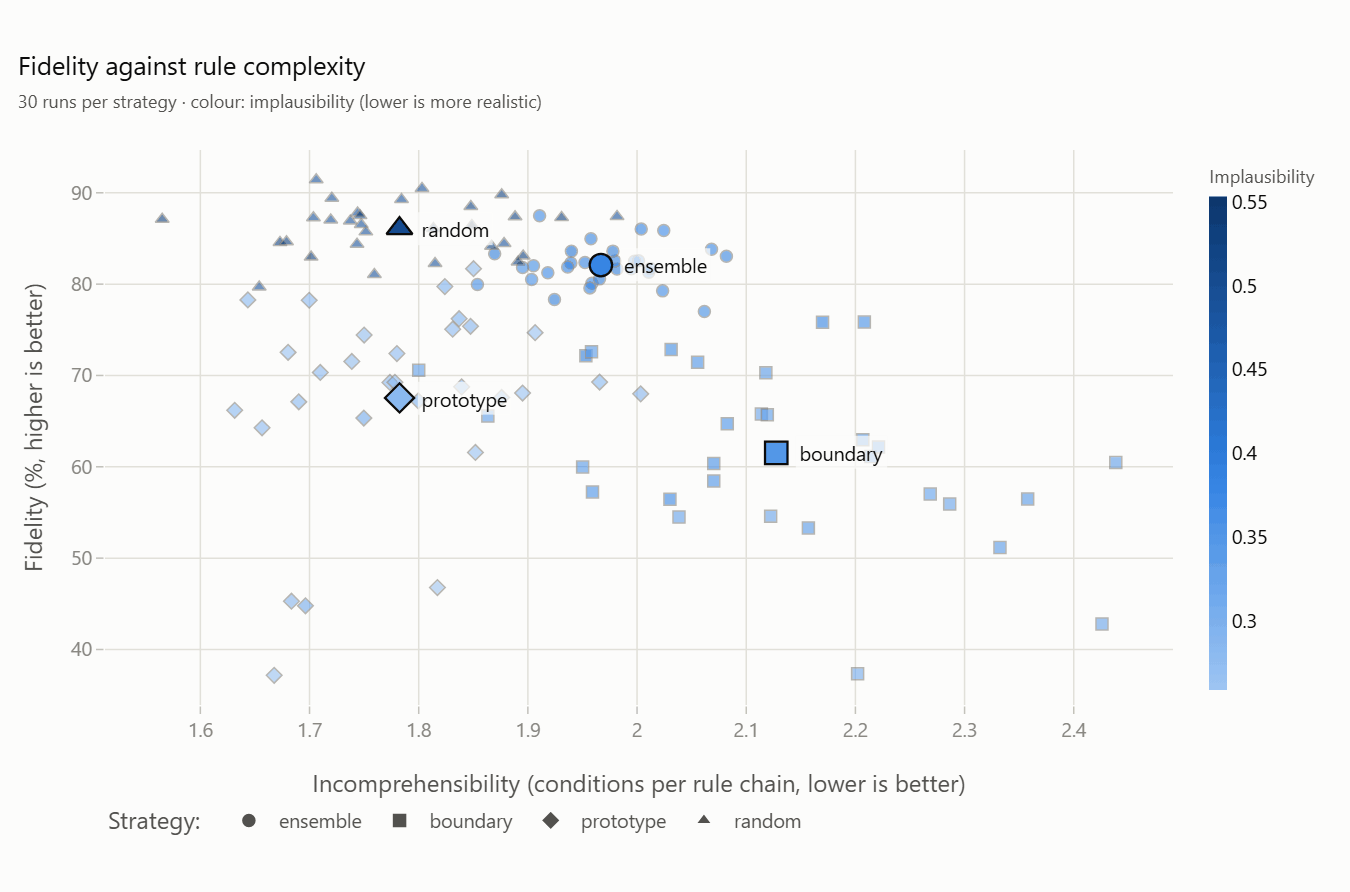

In [10]:
viz.show(viz.plot_pareto(results))

Small markers are single runs, large labelled markers the mean of each strategy. A strategy is on the **Pareto
front** when no other is both more faithful and more concise; a dashed line joins the strategies on it when there are
several. The spread of the small markers shows how much a strategy depends on the split of the data.

On Adult the front has a single strategy: random mining is both the most faithful and the most concise. Its price is
on the third axis, the colour, with the least realistic switches. Prototype and boundary mining pay with fidelity and
with the wide spread of their runs; the ensemble gives up some fidelity and conciseness for more realistic switches
and the most predictable results.

## 5. Make it yours

- **Your own ensemble**: `EnsembleStrategy([BoundaryStrategy(), RandomStrategy()])` combines any strategies, each
  keeping its rules.
- **A wider boundary**: `BoundaryStrategy(n_candidates=300)` draws the factuals among more candidates than the
  default `int(1.5 * s)`.
- **A new strategy**: subclass `ramico.strategies.MiningStrategy`, implement its `select` method and register it by
  name with `register_strategy`.